# ApisTox 蜜蜂急性毒性分类

## 02 分子特征构建

本阶段将使用RDKit把SMILES分子结构转换成机器学习模型能够处理的数值特征。

主要目标：

1. 检查RDKit环境；
2. 将SMILES解析为RDKit分子对象；
3. 验证所有SMILES能否成功解析；
4. 计算可解释的分子描述符；
5. 构建Morgan分子指纹；
6. 保存可重复使用的特征数据。

In [1]:
try:
    import rdkit

    print("RDKit已经安装")
    print("RDKit版本：", rdkit.__version__)

except ImportError:
    print("当前Python环境没有安装RDKit")

RDKit已经安装
RDKit版本： 2024.09.6


In [2]:
import pandas as pd
from rdkit import Chem

data = pd.read_csv("dataset_final.csv")

data[["name", "SMILES"]].head()

,name,SMILES
0,Ethanedioic acid,O=C(O)C(=O)O
1,Para-cymene,Cc1ccc(C(C)C)cc1
2,Kieselguhr,O=[Si]=O
3,Benzoic acid,O=C(O)c1ccccc1
4,Tetradifon (Ref: ENT 23737),O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl


## 1. SMILES有效性检查

使用RDKit将SMILES字符串转换为分子对象。若某个SMILES无法被正确解析，
`Chem.MolFromSmiles()`将返回`None`。无效结构不能直接用于后续分子描述符
和分子指纹的计算，因此需要在特征构建前进行检查。

In [5]:
# 将每个SMILES转换为RDKit分子对象
data["mol"] = data["SMILES"].apply(Chem.MolFromSmiles)

# 判断哪些分子解析失败
invalid_smiles_mask = data["mol"].isna()

total_count = len(data)
valid_count = (~invalid_smiles_mask).sum()
invalid_count = invalid_smiles_mask.sum()

print("化合物总数：", total_count)
print("成功解析数量：", valid_count)
print("解析失败数量：", invalid_count)

化合物总数： 1035
成功解析数量： 1035
解析失败数量： 0


## 2. 规范SMILES与结构重复检查

同一个分子可能存在多种不同的SMILES写法，因此仅检查原始SMILES是否重复，
可能漏掉结构相同但书写方式不同的化合物。

本节使用RDKit生成规范SMILES，并基于规范SMILES检查重复分子。
结构重复可能导致同一分子同时进入训练集和测试集，从而造成数据泄漏。

In [6]:
# 将RDKit分子对象转换为规范SMILES
data["canonical_smiles"] = data["mol"].apply(
    lambda molecule: Chem.MolToSmiles(
        molecule,
        canonical=True,
        isomericSmiles=True
    )
)

data[["SMILES", "canonical_smiles"]].head()

,SMILES,canonical_smiles
0,O=C(O)C(=O)O,O=C(O)C(=O)O
1,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1
2,O=[Si]=O,O=[Si]=O
3,O=C(O)c1ccccc1,O=C(O)c1ccccc1
4,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl


In [7]:
canonical_duplicate_mask = data["canonical_smiles"].duplicated(
    keep=False
)

duplicate_row_count = canonical_duplicate_mask.sum()
duplicate_group_count = data.loc[
    canonical_duplicate_mask,
    "canonical_smiles"
].nunique()

print("规范SMILES唯一数量：", data["canonical_smiles"].nunique())
print("属于重复结构的记录数：", duplicate_row_count)
print("重复结构组数：", duplicate_group_count)

规范SMILES唯一数量： 1035
属于重复结构的记录数： 0
重复结构组数： 0


## 3. 多片段分子检查

部分SMILES可能包含两个或更多互不相连的结构片段，通常使用`.`分隔。
这些记录可能表示盐、离子对、溶剂化物或混合物。

多片段结构会影响分子量、原子数量和其他分子描述符，因此在特征计算前，
需要统计并检查这些记录。本步骤只进行检查，不直接删除或修改分子。

In [8]:
# 统计每个分子包含多少个互不相连的结构片段
data["fragment_count"] = data["mol"].apply(
    lambda molecule: len(Chem.GetMolFrags(molecule))
)

# 统计不同片段数量对应的化合物数量
fragment_count_summary = (
    data["fragment_count"]
    .value_counts()
    .sort_index()
)

fragment_count_summary

fragment_count
1     894
2     103
3      18
4       8
5       8
7       2
8       1
13      1
Name: count, dtype: int64

In [9]:
single_fragment_count = (data["fragment_count"] == 1).sum()
multiple_fragment_count = (data["fragment_count"] > 1).sum()

print("单片段化合物数量：", single_fragment_count)
print("多片段化合物数量：", multiple_fragment_count)
print(
    "多片段化合物比例：",
    round(multiple_fragment_count / len(data) * 100, 2),
    "%"
)

单片段化合物数量： 894
多片段化合物数量： 141
多片段化合物比例： 13.62 %


In [13]:
multiple_fragment_data = (
    data.loc[
        data["fragment_count"] > 1,
        [
            "name",
            "CAS",
            "SMILES",
            "fragment_count",
            "label"
        ]
    ]
    .sort_values(
        "fragment_count",
        ascending=False
    )
)

multiple_fragment_data.head(20)

,name,CAS,SMILES,fragment_count,label
174,Borax,1303-96-4,O.O.O.O.O.O.O.O.O.O.O=BOB([O-])OB([O-])OB=O.[N...,13,0
984,Copper acetoarsenite (Ref: ENT 884),12002-03-8,CC(=O)[O-].CC(=O)[O-].[Cu+2].[Cu+2].[Cu+2].[Cu...,8,1
978,Sodium tetraborate pentahydrate,11130-12-4,O.O.O.O.O.OB(O)O.[Na+],7,0
58,Ferric pyrophosphate,10058-44-3,O=P([O-])([O-])OP(=O)([O-])[O-].O=P([O-])([O-]...,7,0
13,"Sulfuric acid, Iron(3+) salt (3:2)",10028-22-5,O=S(=O)([O-])[O-].O=S(=O)([O-])[O-].O=S(=O)([O...,5,0
59,"Sulfuric acid, Chromium(3+)salt(3:2)",10101-53-8,O=S(=O)([O-])[O-].O=S(=O)([O-])[O-].O=S(=O)([O...,5,0
71,Calcium arsenate,7778-44-1,O=[As]([O-])([O-])[O-].O=[As]([O-])([O-])[O-]....,5,1
975,Prochloraz manganese chloride complex,75747-77-2,CCCN(CCOc1c(Cl)cc(Cl)cc1Cl)C(=O)n1ccnc1.CCCN(C...,5,0
160,Streptomycin sulphate,3810-74-0,CNC1C(OC2C(OC3C(O)C(O)C(N=C(N)N)C(O)C3N=C(N)N)...,5,0
42,Calcium phosphate,10103-46-5,O=P([O-])([O-])[O-].O=P([O-])([O-])[O-].[Ca+2]...,5,0


### 多片段结构与毒性标签的关系

比较单片段和多片段化合物的标签分布，用于判断多片段结构是否与毒性标签
存在明显关联。该分析仅用于数据质量评估，不能证明多片段结构导致毒性变化。

In [14]:
# 根据片段数量划分为单片段和多片段
data["fragment_group"] = (
    data["fragment_count"] > 1
).map({
    False: "单片段",
    True: "多片段"
})

data[["fragment_count", "fragment_group"]].head()

,fragment_count,fragment_group
0,1,单片段
1,1,单片段
2,1,单片段
3,1,单片段
4,1,单片段


In [15]:
fragment_label_counts = pd.crosstab(
    data["fragment_group"],
    data["label"]
).rename(
    columns={
        0: "无毒数量",
        1: "有毒数量"
    }
)

fragment_label_counts

label,无毒数量,有毒数量
fragment_group,,
单片段,622,272
多片段,117,24


In [16]:
fragment_label_percent = (
    pd.crosstab(
        data["fragment_group"],
        data["label"],
        normalize="index"
    )
    .mul(100)
    .round(1)
    .rename(
        columns={
            0: "无毒比例_%",
            1: "有毒比例_%"
        }
    )
)

fragment_label_percent

label,无毒比例_%,有毒比例_%
fragment_group,,
单片段,69.6,30.4
多片段,83.0,17.0


### 多片段结构检查结论

数据集中共有141个多片段化合物，占13.62%。多片段记录主要包括盐、
水合物、金属配合物及无机化合物，因此不将其视为错误数据，也不直接删除。

单片段化合物的有毒比例为30.4%，多片段化合物的有毒比例为17.0%。
该差异仅表示结构形式与标签存在关联，不能解释为多片段结构导致毒性降低，
因为两组的化学类别和数据来源可能不同。

第一版模型保留完整登记结构，但不将片段组别作为输入特征。后续将分别评价
模型在单片段和多片段化合物上的表现。

## 4. 可解释分子描述符构建

使用RDKit根据完整分子结构计算一组具有明确化学意义的二维分子描述符，
包括分子量、脂水分配系数、极性表面积、氢键能力、可旋转键和环结构等。

这些描述符将用于建立可解释的基线模型，并分析分子理化性质与预测结果之间
的统计关联。模型关联不能直接解释为生物学因果机制。

In [17]:
from rdkit.Chem import Descriptors
from rdkit.Chem import Lipinski
from rdkit.Chem import Crippen
from rdkit.Chem import rdMolDescriptors

In [18]:
def calculate_molecular_descriptors(molecule):
    descriptor_values = {
        "MolWt": Descriptors.MolWt(molecule),
        "LogP": Crippen.MolLogP(molecule),
        "TPSA": rdMolDescriptors.CalcTPSA(molecule),
        "HBD": Lipinski.NumHDonors(molecule),
        "HBA": Lipinski.NumHAcceptors(molecule),
        "RotatableBonds": Lipinski.NumRotatableBonds(molecule),
        "RingCount": Lipinski.RingCount(molecule),
        "AromaticRingCount": rdMolDescriptors.CalcNumAromaticRings(
            molecule
        ),
        "HeavyAtomCount": Descriptors.HeavyAtomCount(molecule),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(
            molecule
        ),
        "FormalCharge": sum(
            atom.GetFormalCharge()
            for atom in molecule.GetAtoms()
        )
    }

    return pd.Series(descriptor_values)

In [19]:
descriptor_data = data["mol"].apply(
    calculate_molecular_descriptors
)

descriptor_data.head()

,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,AromaticRingCount,HeavyAtomCount,FractionCSP3,FormalCharge
0,90.034,-0.84440,74.60,2.0,2.0,0.0,0.0,0.0,6.0,0.0,0.0
1,134.222,3.11842,0.00,0.0,0.0,1.0,1.0,1.0,10.0,0.4,0.0
2,60.084,-0.61840,34.14,0.0,2.0,0.0,0.0,0.0,3.0,0.0,0.0
3,122.123,1.38480,37.30,1.0,1.0,1.0,1.0,1.0,9.0,0.0,0.0
4,356.057,5.13300,34.14,0.0,2.0,2.0,2.0,2.0,19.0,0.0,0.0


In [20]:
print("描述符数据维度：", descriptor_data.shape)
print("描述符缺失值总数：", descriptor_data.isna().sum().sum())

descriptor_data.describe().round(2)

描述符数据维度： (1035, 11)
描述符缺失值总数： 0


,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,AromaticRingCount,HeavyAtomCount,FractionCSP3,FormalCharge
count,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00
mean,319.78,2.50,67.05,0.93,4.39,4.40,1.72,1.23,20.31,0.41,0.01
std,151.77,3.10,60.57,1.88,3.36,3.26,1.44,1.03,10.33,0.29,0.19
min,32.07,-20.53,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,-3.00
25%,229.71,1.43,36.92,0.00,2.00,2.00,1.00,0.00,14.00,0.20,0.00
50%,310.30,2.88,55.84,0.00,4.00,4.00,2.00,1.00,20.00,0.36,0.00
75%,379.96,4.19,80.28,1.00,5.00,6.00,2.00,2.00,25.00,0.59,0.00
max,1732.15,19.79,896.66,30.00,47.00,26.00,15.00,8.00,123.00,1.00,3.00


In [21]:
# 找出无法被 RDKit 成功解析的 SMILES
invalid_smiles_mask = data["mol"].isna()

# True 在求和时按 1 计算，因此可得到解析失败的数量
n_invalid_smiles = invalid_smiles_mask.sum()

print(f"SMILES 总数：{len(data)}")
print(f"解析成功：{len(data) - n_invalid_smiles}")
print(f"解析失败：{n_invalid_smiles}")

# 如果存在解析失败的分子，显示对应记录
if n_invalid_smiles > 0:
    display(
        data.loc[
            invalid_smiles_mask,
            ["name", "CAS", "SMILES", "label"]
        ]
    )

SMILES 总数：1035
解析成功：1035
解析失败：0


In [22]:
# 确认原始数据与描述符数据的行索引完全一致
assert data.index.equals(descriptor_data.index), "两张表的行索引不一致"

# 选择检查异常值时需要的化合物信息
audit_columns = [
    "name",
    "CAS",
    "SMILES",
    "label",
    "fragment_count"
]

# 按行索引把化合物信息与分子描述符合并
descriptor_audit = pd.concat(
    [
        data[audit_columns],
        descriptor_data
    ],
    axis=1
)

print("描述符审查表维度：", descriptor_audit.shape)

descriptor_audit.head()

描述符审查表维度： (1035, 16)


,name,CAS,SMILES,label,fragment_count,MolWt,LogP,TPSA,HBD,HBA,RotatableBonds,RingCount,AromaticRingCount,HeavyAtomCount,FractionCSP3,FormalCharge
0,Ethanedioic acid,144-62-7,O=C(O)C(=O)O,0,1,90.034,-0.84440,74.60,2.0,2.0,0.0,0.0,0.0,6.0,0.0,0.0
1,Para-cymene,99-87-6,Cc1ccc(C(C)C)cc1,0,1,134.222,3.11842,0.00,0.0,0.0,1.0,1.0,1.0,10.0,0.4,0.0
2,Kieselguhr,61790-53-2,O=[Si]=O,0,1,60.084,-0.61840,34.14,0.0,2.0,0.0,0.0,0.0,3.0,0.0,0.0
3,Benzoic acid,65-85-0,O=C(O)c1ccccc1,0,1,122.123,1.38480,37.30,1.0,1.0,1.0,1.0,1.0,9.0,0.0,0.0
4,Tetradifon (Ref: ENT 23737),116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,1,1,356.057,5.13300,34.14,0.0,2.0,2.0,2.0,2.0,19.0,0.0,0.0


In [23]:
# 规定审查分子量时需要显示的列
molwt_review_columns = [
    "name",
    "CAS",
    "label",
    "fragment_count",
    "MolWt"
]

# 找出分子量最低的5个化合物
lowest_molwt = descriptor_audit.nsmallest(
    5,
    "MolWt"
)[molwt_review_columns]

# 找出分子量最高的5个化合物
highest_molwt = descriptor_audit.nlargest(
    5,
    "MolWt"
)[molwt_review_columns]

print("分子量最低的5个化合物：")
display(lowest_molwt)

print("分子量最高的5个化合物：")
display(highest_molwt)

分子量最低的5个化合物：


,name,CAS,label,fragment_count,MolWt
162,Sulfur,7704-34-9,0,1,32.067
30,"Cyanamide (Ref: LH 21,810A)",420-04-2,1,1,42.041
315,1-methylcyclopropene,3100-04-7,1,1,54.092
24,Aluminium phosphide,20859-73-8,1,1,57.956
2,Kieselguhr,61790-53-2,0,1,60.084


分子量最高的5个化合物：


,name,CAS,label,fragment_count,MolWt
179,Abamectin (Ref: MK 936),71751-41-2,1,2,1732.153
975,Prochloraz manganese chloride complex,75747-77-2,0,5,1632.528
223,Chitosan hydrochloride,9012-76-4,0,1,1526.464
933,Spinosad (Ref: XDE 105),168316-95-8,1,2,1477.963
160,Streptomycin sulphate,3810-74-0,0,5,1457.397


In [24]:
# 规定检查 LogP 时需要显示的列
logp_review_columns = [
    "name",
    "CAS",
    "label",
    "fragment_count",
    "MolWt",
    "LogP",
    "FormalCharge"
]

# 找出 LogP 最低的5个化合物
lowest_logp = descriptor_audit.nsmallest(
    5,
    "LogP"
)[logp_review_columns]

# 找出 LogP 最高的5个化合物
highest_logp = descriptor_audit.nlargest(
    5,
    "LogP"
)[logp_review_columns]

print("LogP 最低的5个化合物：")
display(lowest_logp)

print("LogP 最高的5个化合物：")
display(highest_logp)

LogP 最低的5个化合物：


,name,CAS,label,fragment_count,MolWt,LogP,FormalCharge
223,Chitosan hydrochloride,9012-76-4,0,1,1526.464,-20.5329,0.0
174,Borax,1303-96-4,0,13,381.371,-18.5830,0.0
160,Streptomycin sulphate,3810-74-0,0,5,1457.397,-18.2806,0.0
974,Glyphosate-sesquisodium (Ref: Mon 8000),70393-85-0,0,5,404.092,-13.2924,0.0
984,Copper acetoarsenite (Ref: ENT 884),12002-03-8,1,8,1013.792,-12.3268,0.0


LogP 最高的5个化合物：


,name,CAS,label,fragment_count,MolWt,LogP,FormalCharge
975,Prochloraz manganese chloride complex,75747-77-2,0,5,1632.528,19.7861,0.0
310,"1,1,1,3,3,3-Hexakis(2-methyl-2-phenylpropyl)di...",13356-08-6,0,1,1052.705,16.7608,0.0
1028,"(1R,3R)-rel-3-[(1Z)-2-Chloro-3,3,3-trifluoro-1...",943012-36-0,1,2,839.178,12.8404,0.0
933,Spinosad (Ref: XDE 105),168316-95-8,1,2,1477.963,11.3649,0.0
1029,"(1S,3S)-rel-3-[(1Z)-2-Chloro-3,3,3-trifluoro-1...",873330-19-9,1,2,933.009,10.8009,0.0


In [25]:
# 选择检查 TPSA 时需要显示的列
tpsa_review_columns = [
    "name",
    "CAS",
    "label",
    "fragment_count",
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA"
]

# 统计 TPSA 等于0的化合物数量
zero_tpsa_count = (descriptor_audit["TPSA"] == 0).sum()

# 找出 TPSA 最高的10个化合物
highest_tpsa = descriptor_audit.nlargest(
    10,
    "TPSA"
)[tpsa_review_columns]

print("TPSA 为0的化合物数量：", zero_tpsa_count)
print(
    "TPSA 为0的化合物比例：",
    round(zero_tpsa_count / len(descriptor_audit) * 100, 2),
    "%"
)

print("TPSA 最高的10个化合物：")
display(highest_tpsa)

TPSA 为0的化合物数量： 49
TPSA 为0的化合物比例： 4.73 %
TPSA 最高的10个化合物：


,name,CAS,label,fragment_count,MolWt,LogP,TPSA,HBD,HBA
160,Streptomycin sulphate,3810-74-0,0,5,1457.397,-18.2806,896.66,30.0,36.0
223,Chitosan hydrochloride,9012-76-4,0,1,1526.464,-20.5329,808.00,29.0,47.0
174,Borax,1303-96-4,0,13,381.371,-18.5830,422.95,0.0,7.0
58,Ferric pyrophosphate,10058-44-3,0,7,745.203,-10.0288,406.83,0.0,21.0
179,Abamectin (Ref: MK 936),71751-41-2,1,2,1732.153,10.3647,340.12,6.0,28.0
981,Sabadilla (Ref: ENT 123 ),8051-02-3,0,2,1265.542,2.3472,338.76,12.0,22.0
576,Polyoxorim,22976-86-9,0,1,521.392,-6.4322,327.05,10.0,14.0
909,Polyoxin B,19396-06-6,0,1,507.409,-6.6381,309.98,10.0,14.0
601,Mildiomycin (Ref: AR-1F1870),67527-71-3,0,1,514.496,-5.5841,307.88,10.0,13.0
984,Copper acetoarsenite (Ref: ENT 884),12002-03-8,1,8,1013.792,-12.3268,274.00,0.0,16.0


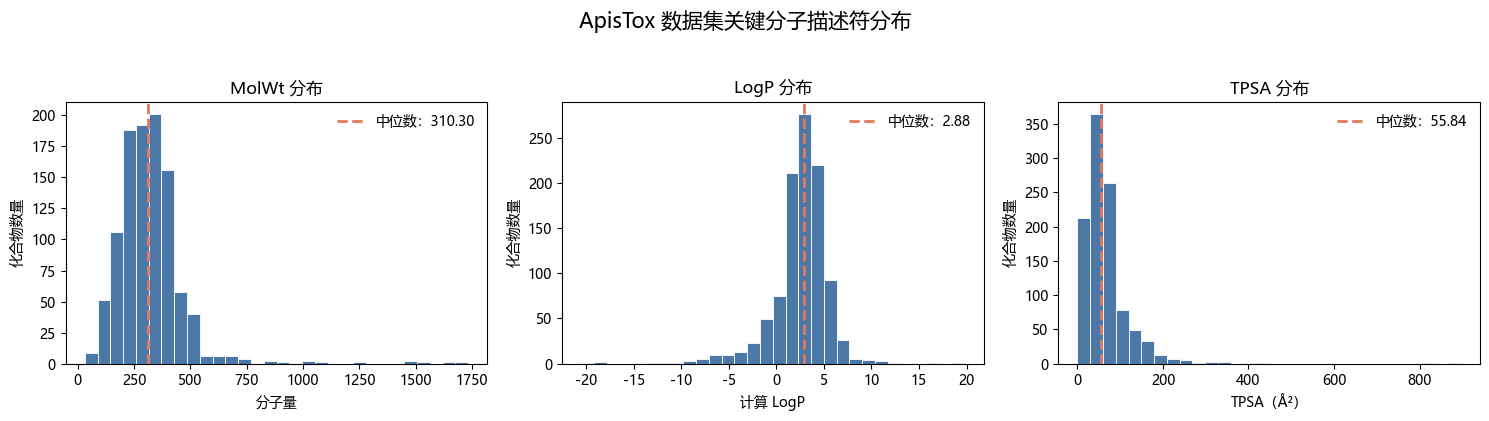

In [26]:
import matplotlib.pyplot as plt

# 设置中文字体和负号显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 创建一行三列的画布
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

# 需要绘制的描述符及其横轴名称
plot_settings = [
    ("MolWt", "分子量"),
    ("LogP", "计算 LogP"),
    ("TPSA", "TPSA（Å²）")
]

# 依次绘制三个描述符的直方图
for axis, (column, x_label) in zip(axes, plot_settings):

    values = descriptor_audit[column]

    axis.hist(
        values,
        bins=30,
        color="#4C78A8",
        edgecolor="white",
        linewidth=0.6
    )

    # 用虚线标出中位数
    axis.axvline(
        values.median(),
        color="#E07A5F",
        linestyle="--",
        linewidth=2,
        label=f"中位数：{values.median():.2f}"
    )

    axis.set_title(f"{column} 分布")
    axis.set_xlabel(x_label)
    axis.set_ylabel("化合物数量")
    axis.legend(frameon=False)

# 设置整张图的标题
fig.suptitle(
    "ApisTox 数据集关键分子描述符分布",
    fontsize=15,
    y=1.04
)

# 自动调整子图间距
plt.tight_layout()

plt.show()

In [27]:
import numpy as np

# 这些描述符理论上应该是非负整数
count_descriptors = [
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount",
    "AromaticRingCount",
    "HeavyAtomCount"
]

# 建立一组基本质量检查
descriptor_quality_checks = {
    "不存在缺失值": descriptor_data.notna().all().all(),

    "不存在无穷值": np.isfinite(
        descriptor_data.to_numpy()
    ).all(),

    "分子量均大于0": (
        descriptor_data["MolWt"] > 0
    ).all(),

    "TPSA均不小于0": (
        descriptor_data["TPSA"] >= 0
    ).all(),

    "FractionCSP3均在0到1之间": (
        descriptor_data["FractionCSP3"]
        .between(0, 1)
        .all()
    ),

    "计数型描述符均不小于0": (
        descriptor_data[count_descriptors] >= 0
    ).all().all(),

    "计数型描述符均为整数值": np.isclose(
        descriptor_data[count_descriptors],
        descriptor_data[count_descriptors].round()
    ).all()
}

# 转换成便于阅读的表格
descriptor_quality_summary = pd.Series(
    descriptor_quality_checks,
    name="是否通过"
).to_frame()

descriptor_quality_summary

,是否通过
不存在缺失值,True
不存在无穷值,True
分子量均大于0,True
TPSA均不小于0,True
FractionCSP3均在0到1之间,True
计数型描述符均不小于0,True
计数型描述符均为整数值,True


In [28]:
# 统计每个描述符有多少个不同取值
unique_value_count = descriptor_data.nunique()

# 找出每个描述符最常见的取值
most_common_value = descriptor_data.apply(
    lambda column: column.value_counts().index[0]
)

# 统计最常见取值出现了多少次
most_common_count = descriptor_data.apply(
    lambda column: column.value_counts().iloc[0]
)

# 建立描述符变异程度汇总表
descriptor_variability = pd.DataFrame({
    "唯一值数量": unique_value_count,
    "最常见值": most_common_value,
    "最常见值数量": most_common_count,
    "最常见值比例_%": (
        most_common_count / len(descriptor_data) * 100
    ).round(2)
})

# 按最常见值比例从高到低排列
descriptor_variability = descriptor_variability.sort_values(
    "最常见值比例_%",
    ascending=False
)

descriptor_variability

,唯一值数量,最常见值,最常见值数量,最常见值比例_%
FormalCharge,6,0.0000,1025,99.03
HBD,14,0.0000,523,50.53
RingCount,13,2.0000,341,32.95
AromaticRingCount,8,1.0000,332,32.08
HBA,22,4.0000,193,18.65
RotatableBonds,22,4.0000,137,13.24
FractionCSP3,153,0.0000,111,10.72
HeavyAtomCount,57,16.0000,60,5.80
TPSA,544,0.0000,49,4.73
MolWt,1011,154.2530,4,0.39


### 描述符筛选决定

`FormalCharge` 在 1035 个化合物中有 1025 个取值为 0，
最常见值比例达到 99.03%，属于近乎常量的特征。

此外，该指标表示整个结构的净形式电荷，无法区分真正的中性分子
与正负电荷相互抵消的盐。因此，第一版描述符模型不使用
`FormalCharge`，但在数据审查表中保留该指标。

其余 10 个描述符暂时保留。该决定仅依据描述符的数值变异程度
和化学含义，没有利用标签与特征的关联进行筛选。

In [29]:
# 第一版模型使用的可解释分子描述符
descriptor_feature_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "RotatableBonds",
    "RingCount",
    "AromaticRingCount",
    "HeavyAtomCount",
    "FractionCSP3"
]

# 建立描述符特征矩阵
descriptor_features = descriptor_data[
    descriptor_feature_columns
].copy()

print("第一版描述符特征矩阵维度：", descriptor_features.shape)
print("使用的描述符：")
print(descriptor_features.columns.tolist())

第一版描述符特征矩阵维度： (1035, 10)
使用的描述符：
['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount', 'AromaticRingCount', 'HeavyAtomCount', 'FractionCSP3']


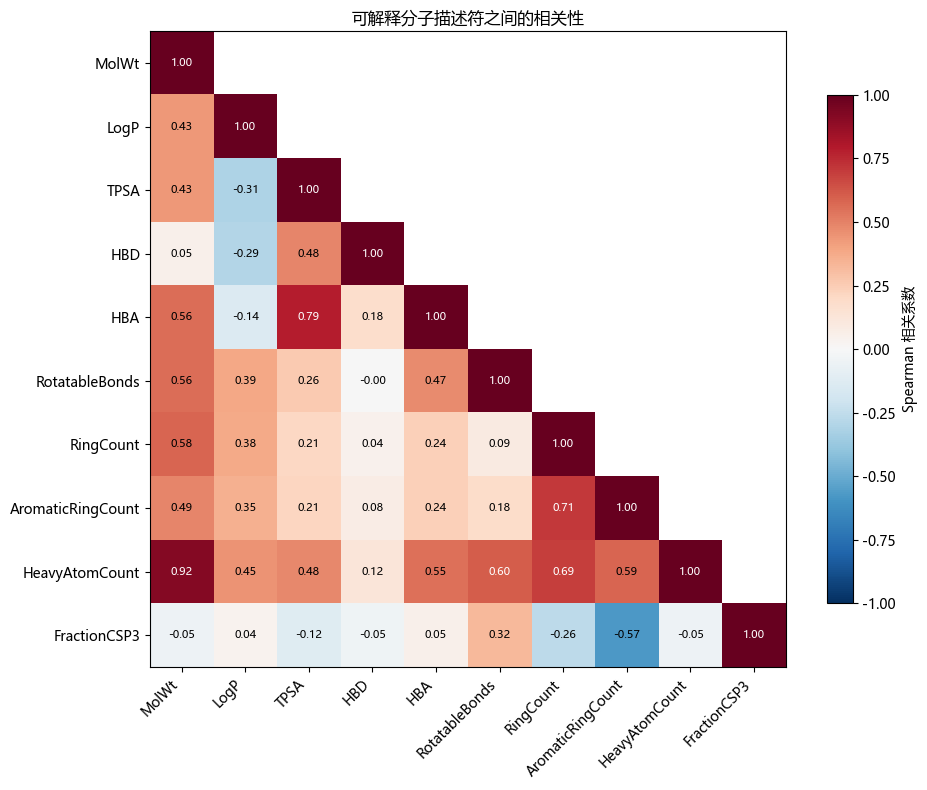

In [30]:
# 计算描述符之间的 Spearman 相关系数
descriptor_correlation = descriptor_features.corr(
    method="spearman"
)

# 创建上三角遮罩，避免显示重复信息
upper_triangle_mask = np.triu(
    np.ones_like(
        descriptor_correlation,
        dtype=bool
    ),
    k=1
)

# 把上三角区域隐藏
correlation_for_plot = np.ma.array(
    descriptor_correlation,
    mask=upper_triangle_mask
)

# 创建画布
fig, ax = plt.subplots(
    figsize=(10, 8)
)

# 绘制相关性矩阵
heatmap = ax.imshow(
    correlation_for_plot,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

# 设置横轴和纵轴标签
ax.set_xticks(
    range(len(descriptor_correlation.columns)),
    labels=descriptor_correlation.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(descriptor_correlation.index)),
    labels=descriptor_correlation.index
)

# 在每个可见方格中写入相关系数
for row in range(len(descriptor_correlation.index)):
    for column in range(len(descriptor_correlation.columns)):

        if not upper_triangle_mask[row, column]:

            correlation_value = descriptor_correlation.iloc[
                row,
                column
            ]

            text_color = (
                "white"
                if abs(correlation_value) >= 0.6
                else "black"
            )

            ax.text(
                column,
                row,
                f"{correlation_value:.2f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=8
            )

# 添加颜色条
colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.8
)

colorbar.set_label("Spearman 相关系数")

ax.set_title(
    "可解释分子描述符之间的相关性"
)

plt.tight_layout()
plt.show()

## 6. Morgan 分子指纹构建

Morgan 指纹把每个分子中的局部原子环境编码成固定长度的二进制向量。
它能够表达比少量二维描述符更细致的局部结构信息，但单个位点通常不容易直接解释。

本项目使用半径为 2、长度为 2048 位并保留手性信息的 Morgan 指纹。
指纹仅由分子结构计算，不使用毒性标签。

In [32]:
from rdkit.Chem import rdFingerprintGenerator
import numpy as np
import pandas as pd

# 重新创建 Morgan 指纹生成器
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True
)

# 为全部化合物计算指纹，并沿行方向堆叠
morgan_array = np.vstack([
    morgan_generator.GetFingerprintAsNumPy(molecule)
    for molecule in data["mol"]
]).astype(np.uint8)

# 创建指纹列名
morgan_column_names = [
    f"MorganBit_{bit_index}"
    for bit_index in range(2048)
]

# 转换为 DataFrame，并保留原始数据索引
morgan_features = pd.DataFrame(
    morgan_array,
    index=data.index,
    columns=morgan_column_names
)

# 基本质量检查
print("Morgan 指纹矩阵维度：", morgan_features.shape)
print("指纹中的不同取值：", np.unique(morgan_array))
print("缺失值总数：", morgan_features.isna().sum().sum())

# 统计每个化合物有多少个位点为1
active_bit_counts = morgan_features.sum(axis=1)

print("\n每个化合物激活位点数量的统计：")
display(active_bit_counts.describe().round(2))

Morgan 指纹矩阵维度： (1035, 2048)
指纹中的不同取值： [0 1]
缺失值总数： 0

每个化合物激活位点数量的统计：


count    1035.00
mean       33.86
std        14.61
min         1.00
25%        24.00
50%        33.00
75%        44.00
max       110.00
dtype: float64

In [33]:
# 统计每个指纹位点在多少个化合物中为1
bit_activation_counts = morgan_features.sum(axis=0)

# 统计不同使用频率的位点数量
unused_bit_count = (
    bit_activation_counts == 0
).sum()

rare_bit_count = (
    (bit_activation_counts >= 1) &
    (bit_activation_counts <= 5)
).sum()

common_bit_count = (
    bit_activation_counts >= len(morgan_features) * 0.8
).sum()

# 计算整个指纹矩阵中1所占的比例
fingerprint_density = (
    morgan_array.mean() * 100
)

print("指纹位点总数：", len(bit_activation_counts))
print("至少出现过一次的位点数：", (bit_activation_counts > 0).sum())
print("从未出现的位点数：", unused_bit_count)
print("仅在1至5个化合物中出现的位点数：", rare_bit_count)
print("在至少80%化合物中出现的位点数：", common_bit_count)
print("整个指纹矩阵中1的比例：", round(fingerprint_density, 2), "%")

指纹位点总数： 2048
至少出现过一次的位点数： 1974
从未出现的位点数： 74
仅在1至5个化合物中出现的位点数： 840
在至少80%化合物中出现的位点数： 0
整个指纹矩阵中1的比例： 1.65 %


In [34]:
# 检查哪些化合物具有完全相同的 Morgan 指纹
duplicate_fingerprint_mask = morgan_features.duplicated(
    keep=False
)

# 为指纹生成一个便于分组的编号
fingerprint_hash = pd.util.hash_pandas_object(
    morgan_features,
    index=False
)

# 建立指纹审查表
fingerprint_audit = data[
    [
        "name",
        "CAS",
        "SMILES",
        "label",
        "fragment_count"
    ]
].copy()

fingerprint_audit["fingerprint_hash"] = fingerprint_hash

# 统计重复指纹记录和重复指纹组
duplicate_fingerprint_row_count = (
    duplicate_fingerprint_mask.sum()
)

duplicate_fingerprint_group_count = (
    fingerprint_audit.loc[
        duplicate_fingerprint_mask,
        "fingerprint_hash"
    ].nunique()
)

# 统计每组重复指纹中包含多少种标签
labels_per_fingerprint = (
    fingerprint_audit.loc[
        duplicate_fingerprint_mask
    ]
    .groupby("fingerprint_hash")["label"]
    .nunique()
)

conflicting_fingerprint_hashes = (
    labels_per_fingerprint[
        labels_per_fingerprint > 1
    ].index
)

print(
    "涉及相同指纹的记录数：",
    duplicate_fingerprint_row_count
)

print(
    "相同指纹组数：",
    duplicate_fingerprint_group_count
)

print(
    "同时包含两种标签的指纹组数：",
    len(conflicting_fingerprint_hashes)
)

# 如果存在相同指纹，显示前20条记录
if duplicate_fingerprint_row_count > 0:

    duplicate_fingerprint_records = (
        fingerprint_audit.loc[
            duplicate_fingerprint_mask
        ]
        .sort_values(
            [
                "fingerprint_hash",
                "label"
            ]
        )
    )

    display(
        duplicate_fingerprint_records.head(20)
    )

涉及相同指纹的记录数： 7
相同指纹组数： 3
同时包含两种标签的指纹组数： 0


,name,CAS,SMILES,label,fragment_count,fingerprint_hash
53,1-decanol,112-30-1,CCCCCCCCCCO,0,1,877954270575632454
84,Myristyl alcohol,112-72-1,CCCCCCCCCCCCCCO,0,1,877954270575632454
28,Hexadecanoic acid,57-10-3,CCCCCCCCCCCCCCCC(=O)O,0,1,9700512214531862260
72,Caprylic acid,124-07-2,CCCCCCCC(=O)O,0,1,9700512214531862260
82,Nonanoic acid,112-05-0,CCCCCCCCC(=O)O,0,1,9700512214531862260
895,Prochloraz manganese complex (Ref: BTS 46828),69192-23-0,CCCN(CCOc1c(Cl)cc(Cl)cc1Cl)C(=O)n1ccnc1.CCCN(C...,0,3,15685814701438206725
975,Prochloraz manganese chloride complex,75747-77-2,CCCN(CCOc1c(Cl)cc(Cl)cc1Cl)C(=O)n1ccnc1.CCCN(C...,0,5,15685814701438206725


In [ ]:
from pathlib import Path

# 创建特征输出文件夹
output_directory = Path("processed_data")
output_directory.mkdir(
    parents=True,
    exist_ok=True
)

# 最后确认三张表的行索引完全一致
assert data.index.equals(descriptor_features.index)
assert data.index.equals(morgan_features.index)
assert data.index.is_unique

# 1. 保存样本信息和标签
sample_metadata = data[
    [
        "name",
        "CID",
        "CAS",
        "SMILES",
        "canonical_smiles",
        "label",
        "fragment_count"
    ]
].copy()

sample_metadata.insert(
    0,
    "sample_id",
    data.index
)

# 2. 保存10个可解释描述符
descriptor_output = descriptor_features.copy()

descriptor_output.insert(
    0,
    "sample_id",
    data.index
)

# 3. 保存2048位 Morgan 指纹
morgan_output = morgan_features.copy()

morgan_output.insert(
    0,
    "sample_id",
    data.index
)

# 写入CSV文件
sample_metadata.to_csv(
    output_directory / "sample_metadata.csv",
    index=False
)

descriptor_output.to_csv(
    output_directory / "descriptor_features.csv",
    index=False
)

morgan_output.to_csv(
    output_directory / "morgan_features.csv",
    index=False
)

print("元数据维度：", sample_metadata.shape)
print("描述符文件维度：", descriptor_output.shape)
print("Morgan指纹文件维度：", morgan_output.shape)

print("\n文件保存位置：")
print(output_directory.resolve())

## 7. 保存特征工程结果

将样本信息、可解释分子描述符和 Morgan 指纹分别保存。
三类数据通过 `sample_id` 对齐，避免把标签或标识符误作为模型输入。

In [ ]:
from pathlib import Path

# 创建输出文件夹
output_directory = Path("processed_data")

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

# 确认三张表的行索引完全一致
assert data.index.equals(descriptor_features.index)
assert data.index.equals(morgan_features.index)
assert data.index.is_unique

# 1. 样本信息与标签
sample_metadata = data[
    [
        "name",
        "CID",
        "CAS",
        "SMILES",
        "canonical_smiles",
        "label",
        "fragment_count"
    ]
].copy()

sample_metadata.insert(
    0,
    "sample_id",
    data.index
)

# 2. 10个可解释分子描述符
descriptor_output = descriptor_features.copy()

descriptor_output.insert(
    0,
    "sample_id",
    data.index
)

# 3. 2048位 Morgan 指纹
morgan_output = morgan_features.copy()

morgan_output.insert(
    0,
    "sample_id",
    data.index
)

# 分别保存
sample_metadata.to_csv(
    output_directory / "sample_metadata.csv",
    index=False
)

descriptor_output.to_csv(
    output_directory / "descriptor_features.csv",
    index=False
)

morgan_output.to_csv(
    output_directory / "morgan_features.csv",
    index=False
)

print("样本信息表维度：", sample_metadata.shape)
print("描述符表维度：", descriptor_output.shape)
print("Morgan指纹表维度：", morgan_output.shape)

print("\n保存文件夹：")
print(output_directory.resolve())

In [37]:
# 重新从硬盘读取三个文件
metadata_check = pd.read_csv(
    output_directory / "sample_metadata.csv"
)

descriptor_check = pd.read_csv(
    output_directory / "descriptor_features.csv"
)

morgan_check = pd.read_csv(
    output_directory / "morgan_features.csv"
)

# 1. 检查文件维度
assert metadata_check.shape == sample_metadata.shape
assert descriptor_check.shape == descriptor_output.shape
assert morgan_check.shape == morgan_output.shape

# 2. 检查三个文件的 sample_id 是否完全一致
assert metadata_check["sample_id"].equals(
    descriptor_check["sample_id"]
)

assert metadata_check["sample_id"].equals(
    morgan_check["sample_id"]
)

# 3. 检查标签数量
label_count_check = (
    metadata_check["label"]
    .value_counts()
    .sort_index()
)

assert label_count_check.to_dict() == {
    0: 739,
    1: 296
}

# 4. 检查描述符数值是否与保存前一致
assert np.allclose(
    descriptor_check[
        descriptor_feature_columns
    ].to_numpy(),
    descriptor_features.to_numpy()
)

# 5. 检查 Morgan 指纹是否与保存前完全一致
assert np.array_equal(
    morgan_check[
        morgan_column_names
    ].to_numpy(dtype=np.uint8),
    morgan_array
)

# 6. 检查是否出现缺失值
assert metadata_check.isna().sum().sum() == 0
assert descriptor_check.isna().sum().sum() == 0
assert morgan_check.isna().sum().sum() == 0

print("三个文件均已成功回读。")
print("sample_id 对齐正确。")
print("标签数量正确：")
print(label_count_check)
print("描述符数值与保存前一致。")
print("Morgan 指纹与保存前一致。")
print("三个文件均无缺失值。")

三个文件均已成功回读。
sample_id 对齐正确。
标签数量正确：
label
0    739
1    296
Name: count, dtype: int64
描述符数值与保存前一致。
Morgan 指纹与保存前一致。
三个文件均无缺失值。
